# Python · Kriging — moderate and high dimension: engineering functions, `normalize`, screening

**Idea.** From 6 to 20 inputs on engineering functions: accuracy, the effect of
`normalize` on inputs in physical units, and the ability of the fitted ranges θ to
tell influential inputs from inactive ones.

**Reference.** The same model on inputs rescaled by hand, and the known active
inputs of the Welch function.

**Tags.** class: Kriging · kernel: matern5_2 ·
topic: high dimension, normalize, screening

| function | d | character |
|---|---|---|
| OTL circuit | 6 | smooth, inputs on very different scales |
| Piston | 7 | smooth, strongly non-linear in a few inputs |
| Borehole | 8 | smooth, 2–3 dominant inputs, raw scales from 0.05 to 10⁵ |
| Robot arm | 8 | oscillating (angles): hard for a stationary GP |
| Dette & Pepelyshev | 8 | curved, logarithmic terms |
| Wing weight | 10 | smooth, nearly additive |
| Welch et al. (1992) | 20 | screening problem: few active inputs, interactions |

Checks:
* **`normalize=True` on raw inputs** gives the same accuracy as an explicit
  rescaling to [0, 1] (they are the same model up to the optimizer);
  inputs in native units (Borehole spans 0.05 to 50 000) must not break a fit;
* Q² floors per function (regression detection);
* the fitted θ of Welch's **inactive** inputs are larger than those of the
  active ones (screening ability, warn-level).

`MLPKriging` on a high-dimensional function with a low-dimensional structure:
`deep-kernel-projected-branin_MLPKriging_python.ipynb`.

In [1]:
# Setup for running this notebook outside the repository (Colab, Binder, a lone copy):
# nothing to do in the repository itself (CI, local runs). Otherwise the repository
# (datasets of data/, helpers of tools/python/gallery.py) is cloned and the released pylibkriging installed.
import importlib
import os
import subprocess
import sys
from pathlib import Path

if not Path("tools/known_issues.csv").is_file():
    if not Path("gallery/tools/known_issues.csv").is_file():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/libKriging/gallery"], check=True)
    os.chdir("gallery")
    try:
        import pylibkriging  # noqa: F401
    except ImportError:
        r = subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "pylibkriging"],
                           capture_output=True, text=True)
        if r.returncode != 0:
            raise RuntimeError(
                f"pylibkriging could not be installed for Python {sys.version_info.major}.{sys.version_info.minor} "
                "(PyPI has wheels for CPython 3.10 to 3.12 only). On Colab: Runtime > Change runtime version > "
                "2026.07 (Python 3.12), then run again.\n" + r.stderr[-500:])
        importlib.invalidate_caches()
sys.path.insert(0, str(Path("tools/python").resolve()))  # for "import gallery" (tools/python/gallery.py)
print("working directory:", os.getcwd())

working directory: /home/runner/work/gallery/gallery


In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pylibkriging as lk

import gallery
from gallery import TESTS, design, metrics, compat

suite = gallery.Suite("high-dimension-normalize-screening_Kriging_python")
print("pylibkriging", compat.version())


def pred(k, X):
    m, s, *_ = k.predict(X, return_stdev=True)
    return np.ravel(m), np.ravel(s)

pylibkriging 1.2.2


## Accuracy, unit-cube inputs vs native inputs with `normalize=True`

In [3]:
CASES = {  # function: (n, Q2 floor on the unit cube)
    "otl_circuit": (60, 0.999),
    "piston": (70, 0.98),
    "borehole": (80, 0.995),
    "robot_arm": (160, 0.45),
    "dette_pepelyshev": (80, 0.99),
    "wing_weight": (100, 0.999),
    "welch": (200, 0.98),
}
for fname, (n, floor) in CASES.items():
    tf = TESTS[fname]
    U, y, Ut, yt = design.dataset(tf, n, n_test=2000, seed=41)
    t0 = time.time()
    k = lk.Kriging(y, U, "matern5_2")
    fit_s = time.time() - t0
    res = metrics.all_metrics(yt, *pred(k, Ut))
    suite.metric(fname, "unit cube", fit_s=fit_s, **res)
    suite.check_greater(f"{fname}: Q2 (unit cube, matern5_2)", res["q2"], floor)
    # same problem in native units, rescaled internally
    Xn, Xtn = tf.scale(U), tf.scale(Ut)
    with suite.check_runs(f"{fname}: fit on native inputs with normalize=True"):
        kn = lk.Kriging(y, Xn, "matern5_2", normalize=True)
        res_n = metrics.all_metrics(yt, *pred(kn, Xtn))
        suite.metric(fname, "native + normalize", **res_n)
        suite.check_greater(f"{fname}: Q2(normalize) - Q2(unit cube)", res_n["q2"] - res["q2"], -0.02)
tab = suite.table()
tab.round(4)

metric                                fit_s    rmse      q2    nlpd  \
case             package                                              
otl_circuit      unit cube           0.0045  0.0151  0.9998 -2.9045   
                 native + normalize     NaN  0.0151  0.9998 -2.9045   
piston           unit cube           0.0089  0.0104  0.9945 -3.4904   
                 native + normalize     NaN  0.0104  0.9945 -3.4904   
borehole         unit cube           0.0072  0.8933  0.9996  1.0843   
                 native + normalize     NaN  0.8933  0.9996  1.0843   
robot_arm        unit cube           0.0983  0.3585  0.5712  0.3551   
                 native + normalize     NaN  0.3585  0.5712  0.3551   
dette_pepelyshev unit cube           0.0092  0.4249  0.9978  0.5103   
                 native + normalize     NaN  0.4249  0.9978  0.5103   
wing_weight      unit cube           0.0152  0.8097  0.9997  1.0716   
                 native + normalize     NaN  0.8097  0.9997  1.0716   
welch            unit cube           0.3967  0.1677  0.9935 -0.4291   
                 native + normalize     NaN  0.1677  0.9935 -0.4293   

metric                               coverage95    crps  
case             package                                 
otl_circuit      unit cube               0.9430  0.0080  
                 native + normalize      0.9430  0.0080  
piston           unit cube               0.9165  0.0046  
                 native + normalize      0.9165  0.0046  
borehole         unit cube               0.9530  0.4291  
                 native + normalize      0.9530  0.4291  
robot_arm        unit cube               0.9210  0.1971  
                 native + normalize      0.9210  0.1971  
dette_pepelyshev unit cube               0.9860  0.2299  
                 native + normalize      0.9860  0.2299  
wing_weight      unit cube               0.9600  0.4164  
                 native + normalize      0.9600  0.4164  
welch            unit cube               0.9895  0.0893  
                 native + normalize      0.9895  0.0893

## Screening: Welch et al. (1992)

Inputs 8 and 16 do not appear in the function; inputs 1, 4, 5, 12, 19, 20 are
the most influential ones. A small θ_j (short correlation length) means an
influential input, so the inactive inputs should get the largest θ.

[WARN] welch: min theta(inactive) / max theta(active): value=0.997655 expected > 1 


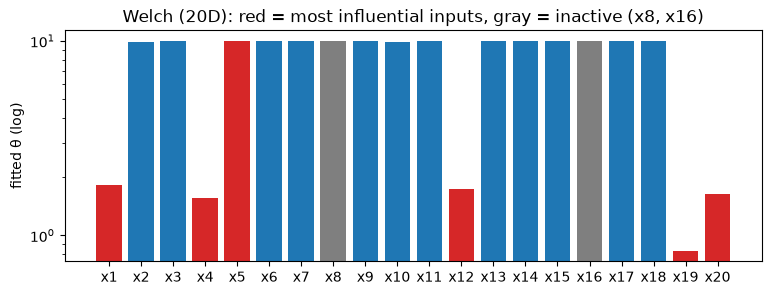

,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,x11,x12,x13,x14,x15,x16,x17,x18,x19,x20
theta,1.817,9.925,9.953,1.565,9.973,9.978,9.947,9.949,9.998,9.916,9.938,1.737,9.979,9.945,9.944,9.956,9.958,9.944,0.832,1.637


In [4]:
tf = TESTS["welch"]
U, y, _, _ = design.dataset(tf, 200, seed=42)
k = lk.Kriging(y, U, "matern5_2")
theta = np.ravel(k.theta())
inactive = [7, 15]            # 0-based indices of x8, x16
active = [0, 3, 4, 11, 18, 19]  # x1, x4, x5, x12, x19, x20
suite.check_greater("welch: min theta(inactive) / max theta(active)", theta[inactive].min() / theta[active].max(), 1.0,
              severity="warn")
colors = ["tab:red" if i in active else "tab:gray" if i in inactive else "tab:blue" for i in range(20)]
plt.figure(figsize=(9, 3))
plt.bar([f"x{i + 1}" for i in range(20)], theta, color=colors)
plt.yscale("log"); plt.ylabel("fitted θ (log)")
plt.title("Welch (20D): red = most influential inputs, gray = inactive (x8, x16)"); plt.show()
pd.Series(theta, index=[f"x{i + 1}" for i in range(20)]).round(3).to_frame("theta").T

## Summary

The metrics of this notebook, the number of checks per status, and every check that
did not pass (FAIL: error-level, fails the run; WARN: warn-level; KNOWN: listed in
`tools/known_issues.csv`, with its issue; SKIP: feature absent from the installed version).
All of them are also written to `results/high-dimension-normalize-screening_Kriging_python.checks.csv` and `.metrics.csv`.

In [5]:
suite.summary()

metric                                fit_s    rmse      q2    nlpd  \
case             package                                              
otl_circuit      unit cube           0.0045  0.0151  0.9998 -2.9045   
                 native + normalize     NaN  0.0151  0.9998 -2.9045   
piston           unit cube           0.0089  0.0104  0.9945 -3.4904   
                 native + normalize     NaN  0.0104  0.9945 -3.4904   
borehole         unit cube           0.0072  0.8933  0.9996  1.0843   
                 native + normalize     NaN  0.8933  0.9996  1.0843   
robot_arm        unit cube           0.0983  0.3585  0.5712  0.3551   
                 native + normalize     NaN  0.3585  0.5712  0.3551   
dette_pepelyshev unit cube           0.0092  0.4249  0.9978  0.5103   
                 native + normalize     NaN  0.4249  0.9978  0.5103   
wing_weight      unit cube           0.0152  0.8097  0.9997  1.0716   
                 native + normalize     NaN  0.8097  0.9997  1.0716   
welch            unit cube           0.3967  0.1677  0.9935 -0.4291   
                 native + normalize     NaN  0.1677  0.9935 -0.4293   

metric                               coverage95    crps  
case             package                                 
otl_circuit      unit cube               0.9430  0.0080  
                 native + normalize      0.9430  0.0080  
piston           unit cube               0.9165  0.0046  
                 native + normalize      0.9165  0.0046  
borehole         unit cube               0.9530  0.4291  
                 native + normalize      0.9530  0.4291  
robot_arm        unit cube               0.9210  0.1971  
                 native + normalize      0.9210  0.1971  
dette_pepelyshev unit cube               0.9860  0.2299  
                 native + normalize      0.9860  0.2299  
wing_weight      unit cube               0.9600  0.4164  
                 native + normalize      0.9600  0.4164  
welch            unit cube               0.9895  0.0893  
                 native + normalize      0.9895  0.0893

22 checks: PASS 21, FAIL 0, WARN 1, KNOWN 0, SKIP 0


,status,severity,check,value,expected,detail
0,WARN,warn,welch: min theta(inactive) / max theta(active),0.997655,> 1,


In [6]:
suite.finalize()

high-dimension-normalize-screening_Kriging_python: PASS 21, FAIL 0, WARN 1, KNOWN 0, SKIP 0


{'PASS': 21, 'FAIL': 0, 'WARN': 1, 'KNOWN': 0, 'SKIP': 0}